# 10. Tutorial 10

**Course:** High Switching Frequency Power Converters

## 10.1 Class E inverter for brief B4

$15~\mathrm{W}$ from $24~\mathrm{V}$ at $6.78~\mathrm{MHz}$, $D = 0.5$. Transistor: $C_\mathrm{oss}(v) = C_0/\sqrt{1 + v/V_\mathrm{j}}$, $C_0 = 443~\mathrm{pF}$, $V_\mathrm{j} = 5~\mathrm{V}$ (Tutorial 8). Design coefficients ($Q_\mathrm{L} = \omega L/R$ with the whole series inductance):

| | $RP/V_\mathrm{DC}^2$ | $\omega C_\mathrm{sh}R$ | $X/R$ | $V_\mathrm{S,pk}/V_\mathrm{DC}$ |
|---|---|---|---|---|
| $Q_\mathrm{L}\to\infty$ | 0.5768 | 0.1836 | 1.1525 | 3.562 |
| $Q_\mathrm{L} = 5$ | 0.5167 | 0.2091 | 1.2855 | 3.616 |

10.1.1 Import necessary modules (numpy as np, matplotlib.pyplot as plt, scipy.optimize) and create the functions
- `get_classE(P, V, f, QL)`: $R$, $C_\mathrm{sh}$, $X$, $L$, $C_0$ and the peak voltage for $Q_\mathrm{L} = \infty$ or $5$,
- `get_Coss(v)`: output capacitance of the transistor,
- `get_fmax(P, V, C)`: device-limited maximum frequency.

Print the ideal and the $Q_\mathrm{L} = 5$ design, the small-signal $C_\mathrm{oss}(24~\mathrm{V})$, $f_\mathrm{max}$ and the remaining external capacitance.

10.1.2 Create the function `make_period(C_sh, R, L, C0, V, f, L_F, n, clamp)` that integrates one period of the class E inverter (states $i_\mathrm{F}$, $v_\mathrm{S}$, $i_\mathrm{o}$, $v_{C0}$, RK4 with $n$ steps, switch on for the first half period, body diode clamping $v_\mathrm{S}$ at zero if `clamp=True`; `C_sh` is a function of $v_\mathrm{S}$) and the function `steady(period, x0)` that finds the periodic steady state by shooting. Simulate the $Q_\mathrm{L} = 5$ design with a linear $C_\mathrm{sh}$ and $L_\mathrm{F} = 100~\mu\mathrm{H}$ for $R/R_\mathrm{nom} = 0.5, 0.75, 1, 1.5, 2$. Print the voltage at turn-on, the peak voltage, the output power and the turn-on loss, and plot the drain voltage for $0.5$, $1$ and $2\,R_\mathrm{nom}$.


In [1]:
# Subtask 10.1.1 Import necessary modules and create the functions
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize

COEF = {np.inf: (0.5768, 0.1836, 1.1525, 3.562), 5.0: (0.5167, 0.2091, 1.2855, 3.616)}


def get_classE(P, V, f, QL=np.inf):
    """Class E design for D = 0.5: R, C_sh, X, L, C0 (L and C0 only for finite QL) and peak voltage."""
    kR, kC, kX, kV = COEF[QL]
    w = 2 * np.pi * f
    R = kR * V**2 / P
    C_sh = kC / (w * R)
    X = kX * R
    if np.isfinite(QL):
        L = QL * R / w
        C0 = 1 / (w * (w * L - X))
    else:
        L, C0 = np.nan, np.nan
    return dict(R=R, C_sh=C_sh, X=X, L=L, C0=C0, V_pk=kV * V)


def get_Coss(v, C0=443e-12, Vj=5.0):
    """Output capacitance of the 100 V GaN transistor of Tutorial 8 (junction model)."""
    return C0 / np.sqrt(1 + np.maximum(v, -0.9 * Vj) / Vj)


def get_fmax(P, V, C):
    """Device-limited maximum frequency of the ideal class E (C_sh = C)."""
    return 0.0507 * P / (C * V**2)


P, V, f = 15.0, 24.0, 6.78e6
w = 2 * np.pi * f
d_id = get_classE(P, V, f)
d5 = get_classE(P, V, f, 5.0)
I_dc = P / V
print(f"ideal: R = {d_id['R']:.2f} Ohm, C_sh = {d_id['C_sh']*1e12:.1f} pF, X = {d_id['X']:.2f} Ohm ({d_id['X']/w*1e9:.0f} nH), "
      f"V_pk = {d_id['V_pk']:.1f} V, I_DC = {I_dc:.3f} A, I_pk = {2.862*I_dc:.2f} A")
C24 = get_Coss(24.0)
print(f"C_oss(24 V) = {C24*1e12:.1f} pF, f_max = {get_fmax(P, V, C24)/1e6:.2f} MHz, C_ext = {(d_id['C_sh']-C24)*1e12:.1f} pF")
print(f"QL = 5: R = {d5['R']:.2f} Ohm, C_sh = {d5['C_sh']*1e12:.1f} pF (C_ext = {(d5['C_sh']-C24)*1e12:.1f} pF), X = {d5['X']:.2f} Ohm, "
      f"L = {d5['L']*1e6:.3f} uH, C0 = {d5['C0']*1e12:.1f} pF, V_pk = {d5['V_pk']:.1f} V")
i_o = np.sqrt(2 * P / d5['R'])
print(f"series inductor, Q_ind = 150: ESR = {w*d5['L']/150:.3f} Ohm, loss = {i_o**2*w*d5['L']/150/2:.2f} W")


ideal: R = 22.15 Ohm, C_sh = 194.6 pF, X = 25.53 Ohm (599 nH), V_pk = 85.5 V, I_DC = 0.625 A, I_pk = 1.79 A
C_oss(24 V) = 183.9 pF, f_max = 7.18 MHz, C_ext = 10.6 pF
QL = 5: R = 19.84 Ohm, C_sh = 247.4 pF (C_ext = 63.4 pF), X = 25.51 Ohm, L = 2.329 uH, C0 = 318.5 pF, V_pk = 86.8 V
series inductor, Q_ind = 150: ESR = 0.661 Ohm, loss = 0.50 W


R = 0.50 R_nom: v_on =   0.0 V, V_pk = 100.4 V, P = 11.80 W, turn-on loss = 0.00 W


R = 0.75 R_nom: v_on =   0.0 V, V_pk =  94.6 V, P = 14.59 W, turn-on loss = 0.00 W


R = 1.00 R_nom: v_on =   0.0 V, V_pk =  87.4 V, P = 15.11 W, turn-on loss = 0.00 W


R = 1.50 R_nom: v_on =  23.0 V, V_pk =  74.0 V, P = 13.29 W, turn-on loss = 0.44 W


R = 2.00 R_nom: v_on =  37.1 V, V_pk =  66.6 V, P = 12.18 W, turn-on loss = 1.16 W


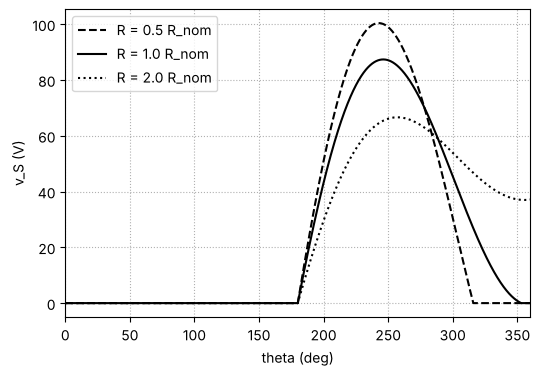

In [2]:
# Subtask 10.1.2 Time-domain model and load variation
def make_period(C_sh, R, L, C0, V=24.0, f=6.78e6, L_F=100e-6, n=2000, clamp=True):
    """Returns period(x0[, record]) for the class E with x = [i_F, v_S, i_o, v_C0] at the end of the off interval."""
    T = 1 / f
    dt, n_on = T / n, n // 2

    def deriv(x, on):
        i_F, v, i_o, v_c = x
        if on:          # switch or body diode conducts: v_S = 0
            return np.array([V / L_F, 0.0, (-v_c - R * i_o) / L, i_o / C0])
        return np.array([(V - v) / L_F, (i_F - i_o) / C_sh(v), (v - v_c - R * i_o) / L, i_o / C0])

    def period(x0, record=False):
        x = np.array(x0, float)
        x[1] = 0.0                                   # switch closes
        rec = [x.copy()]
        diode = False
        for k in range(n):
            on = k < n_on or diode
            k1 = deriv(x, on); k2 = deriv(x + 0.5 * dt * k1, on)
            k3 = deriv(x + 0.5 * dt * k2, on); k4 = deriv(x + dt * k3, on)
            x = x + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
            if k >= n_on:
                if clamp and not on and x[1] < 0.0:   # body diode takes over
                    x[1], diode = 0.0, True
                elif diode and x[0] - x[2] > 0.0:     # diode current ends
                    diode = False
            rec.append(x.copy())
        return (x, np.array(rec)) if record else x
    return period


def steady(period, x0):
    """Periodic steady state by shooting."""
    return optimize.fsolve(lambda x: period(x) - x, x0, xtol=1e-10)


def evaluate(period, x0, C_lin=None):
    """Steady state, waveform and figures of merit."""
    x = steady(period, x0)
    _, rec = period(x, True)
    th = np.linspace(0, 360, len(rec))
    P_in = V * np.mean(rec[:, 0])
    P_on = 0.5 * C_lin * max(x[1], 0)**2 * f if C_lin is not None else np.nan
    return dict(x=x, th=th, v=rec[:, 1], v_on=x[1], i_on=x[0] - x[2], V_pk=rec[:, 1].max(), P=P_in, P_on=P_on)


x0 = np.array([0.7, 0.0, 0.3, 0.0])
res = {}
for Rf in (0.5, 0.75, 1.0, 1.5, 2.0):
    per = make_period(lambda v: d5['C_sh'], Rf * d5['R'], d5['L'], d5['C0'])
    r = evaluate(per, x0, d5['C_sh'])
    x0 = r['x']
    res[Rf] = r
    print(f"R = {Rf:4.2f} R_nom: v_on = {r['v_on']:5.1f} V, V_pk = {r['V_pk']:5.1f} V, P = {r['P']:5.2f} W, "
          f"turn-on loss = {r['P_on']:.2f} W")

plt.figure(figsize=(6, 4))
for Rf, ls in ((0.5, '--'), (1.0, '-'), (2.0, ':')):
    plt.plot(res[Rf]['th'], res[Rf]['v'], 'k' + ls, label=f'R = {Rf} R_nom')
plt.xlabel('theta (deg)'); plt.ylabel('v_S (V)'); plt.xlim(0, 360); plt.grid(True, ls=':'); plt.legend(); plt.show()


### 10.1 Solution

Ideal design: $R = 22.1~\Omega$, $C_\mathrm{sh} = 194.6~\mathrm{pF}$, $X = 25.5~\Omega$, $V_\mathrm{S,pk} = 85.5~\mathrm{V}$, $I_\mathrm{DC} = 0.625~\mathrm{A}$, $I_\mathrm{S,pk} = 1.79~\mathrm{A}$. $C_\mathrm{oss}(24~\mathrm{V}) = 184~\mathrm{pF}$ gives $f_\mathrm{max} = 7.18~\mathrm{MHz}$: only $10.6~\mathrm{pF}$ remain for layout and external capacitor. With $Q_\mathrm{L} = 5$: $R = 19.8~\Omega$, $C_\mathrm{sh} = 247.4~\mathrm{pF}$ ($C_\mathrm{ext} = 63.4~\mathrm{pF}$), $L = 2.33~\mu\mathrm{H}$, $C_0 = 318.5~\mathrm{pF}$; the series inductor dissipates $0.50~\mathrm{W}$.

Load variation: below $R_\mathrm{nom}$ the body diode conducts before turn-on and the peak rises to $100~\mathrm{V}$ at $0.5\,R_\mathrm{nom}$; above $R_\mathrm{nom}$ the turn-on is hard ($23~\mathrm{V}$ and $0.44~\mathrm{W}$ at $1.5\,R_\mathrm{nom}$, $37~\mathrm{V}$ and $1.16~\mathrm{W}$ at $2\,R_\mathrm{nom}$). The output power stays between $11.8$ and $15.1~\mathrm{W}$.


## 10.2 Nonlinear output capacitance

10.2.1 Print $C_\mathrm{oss}$ at $0$, $24$ and $87.4~\mathrm{V}$ and the charge-equivalent capacitance $Q_\mathrm{oss}/V$ for a swing from $0$ to $87.4~\mathrm{V}$.

10.2.2 Simulate the $Q_\mathrm{L} = 5$ design with $C_\mathrm{sh} = C_\mathrm{oss}(v) + 63.4~\mathrm{pF}$. Then retune $C_\mathrm{ext}$ and $X$ with `scipy.optimize.fsolve` for $v_\mathrm{S} = 0$ and $\mathrm{d}v_\mathrm{S}/\mathrm{d}t = 0$ at turn-on (unknowns: the four states, $C_\mathrm{ext}$ and $X$; no diode clamp during the search). Print the voltage at turn-on, the capacitor current at turn-on, the peak voltage and the power, and plot the three drain voltages (linear, nonlinear, retuned).


In [3]:
# Subtask 10.2.1 Nonlinear output capacitance
def get_Qoss(V, C0=443e-12, Vj=5.0):
    """Charge of the junction model from 0 to V."""
    return 2 * C0 * Vj * (np.sqrt(1 + V / Vj) - 1)


for v in (0.0, 24.0, 87.4):
    print(f"C_oss({v:4.1f} V) = {get_Coss(v)*1e12:6.1f} pF")
print(f"Q_oss(87.4 V) = {get_Qoss(87.4)*1e9:.2f} nC, Q_oss/V = {get_Qoss(87.4)/87.4*1e12:.1f} pF")


C_oss( 0.0 V) =  443.0 pF
C_oss(24.0 V) =  183.9 pF
C_oss(87.4 V) =  103.1 pF
Q_oss(87.4 V) = 14.61 nC, Q_oss/V = 167.2 pF


linear 247.4 pF: v_on = 0.00 V, i at turn-on = 5 mA, V_pk = 87.4 V, P = 15.11 W
C_oss(v) + 63.4 pF: v_on = 0.89 V, i at turn-on = 95 mA, V_pk = 100.1 V, P = 16.23 W
retuned: C_ext = 66.5 pF, X = 27.44 Ohm: v_on = -0.00 V, i at turn-on = 0 mA, V_pk = 98.3 V, P = 14.68 W
X was 25.51 Ohm, C0 = 327.1 pF


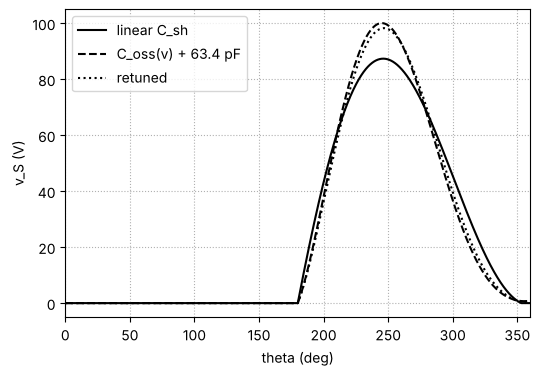

In [4]:
# Subtask 10.2.2 Simulation with C_oss(v) and retuning
C_ext0 = d5['C_sh'] - get_Coss(24.0)
per_lin = make_period(lambda v: d5['C_sh'], d5['R'], d5['L'], d5['C0'])
r_lin = evaluate(per_lin, res[1.0]['x'])
per_nl = make_period(lambda v: get_Coss(v) + C_ext0, d5['R'], d5['L'], d5['C0'])
r_nl = evaluate(per_nl, r_lin['x'])
X_old = w * d5['L'] - 1 / (w * d5['C0'])


def equations(p):
    """Periodicity, ZVS and zero dv/dt; unknowns: four states, C_ext (pF) and X (Ohm)."""
    x, C_ext, X = p[:4], p[4] * 1e-12, p[5]
    C0 = 1 / (w * (w * d5['L'] - X))
    per = make_period(lambda v: get_Coss(v) + C_ext, d5['R'], d5['L'], C0, clamp=False)
    x_end = per(x)
    return list(x_end - x) + [x_end[1], x_end[0] - x_end[2]]


sol = optimize.fsolve(equations, np.concatenate([r_nl['x'], [C_ext0 * 1e12, X_old]]), xtol=1e-9)
C_ext1, X_new = sol[4] * 1e-12, sol[5]
C0_new = 1 / (w * (w * d5['L'] - X_new))
per_tuned = make_period(lambda v: get_Coss(v) + C_ext1, d5['R'], d5['L'], C0_new)
r_tuned = evaluate(per_tuned, sol[:4])
for name, r in (('linear 247.4 pF', r_lin), (f'C_oss(v) + {C_ext0*1e12:.1f} pF', r_nl), (f'retuned: C_ext = {C_ext1*1e12:.1f} pF, X = {X_new:.2f} Ohm', r_tuned)):
    print(f"{name}: v_on = {r['v_on']:.2f} V, i at turn-on = {r['i_on']*1e3:.0f} mA, V_pk = {r['V_pk']:.1f} V, P = {r['P']:.2f} W")
print(f"X was {X_old:.2f} Ohm, C0 = {C0_new*1e12:.1f} pF")

plt.figure(figsize=(6, 4))
plt.plot(r_lin['th'], r_lin['v'], 'k-', label='linear C_sh')
plt.plot(r_nl['th'], r_nl['v'], 'k--', label='C_oss(v) + 63.4 pF')
plt.plot(r_tuned['th'], r_tuned['v'], 'k:', label='retuned')
plt.xlabel('theta (deg)'); plt.ylabel('v_S (V)'); plt.xlim(0, 360); plt.grid(True, ls=':'); plt.legend(); plt.show()


### 10.2 Solution

$C_\mathrm{oss}$ falls from $443~\mathrm{pF}$ at $0~\mathrm{V}$ to $184~\mathrm{pF}$ at $24~\mathrm{V}$ and $103~\mathrm{pF}$ at the peak; $Q_\mathrm{oss}/V = 167~\mathrm{pF}$ for the full swing. With $C_\mathrm{ext} = 63.4~\mathrm{pF}$ the drain is still nearly at zero at turn-on ($0.9~\mathrm{V}$), but the slope is no longer zero and the peak rises from $87.4~\mathrm{V}$ to $100.1~\mathrm{V}$. Retuning ($C_\mathrm{ext} = 66.5~\mathrm{pF}$, $X = 27.4~\Omega$) restores ZVS and zero $\mathrm{d}v/\mathrm{d}t$, but the peak stays at $98.3~\mathrm{V}$: a $100~\mathrm{V}$ transistor is not acceptable for this design.


## 10.3 Matching networks

$Q_\mathrm{ind} = 150$, $Q_\mathrm{cap} = 1000$.

10.3.1 Create the functions
- `get_Lsection(R_high, R_low, f)`: $Q$, series inductance and shunt capacitance of a low-pass L-section,
- `get_pi(R_high, R_low, Q1, f)`: virtual resistance, $Q_2$ and the elements of a low-pass $\pi$ network,
- `get_eta(Q_sum)`: efficiency $1 - Q_\mathrm{sum}/Q_\mathrm{ind} - Q_\mathrm{sum}/Q_\mathrm{cap}$.

Design the L-section from $33.2~\Omega$ to $8~\Omega$ and the networks from $50~\Omega$ to $5~\Omega$ (L-section and $\pi$ with $Q_1 = 4$) at $13.56~\mathrm{MHz}$ and print the values and efficiencies.

10.3.2 Create a function `smith_axes(ax)` that draws a Smith chart (constant-resistance and constant-reactance circles) and draw the matching paths of both $50~\Omega$ to $5~\Omega$ networks in it. Plot $|\Gamma|$ with respect to $50~\Omega$ from $10$ to $17~\mathrm{MHz}$ and print the band with $|\Gamma| \leq 0.2$.


In [5]:
# Subtask 10.3.1 L-section and pi network
Q_ind, Q_cap = 150.0, 1000.0


def get_Lsection(R_high, R_low, f):
    """Low-pass L-section: transformation Q, series L (low side), shunt C (high side)."""
    w = 2 * np.pi * f
    Q = np.sqrt(R_high / R_low - 1)
    return Q, Q * R_low / w, Q / (w * R_high)


def get_pi(R_high, R_low, Q1, f):
    """Low-pass pi network as two L-sections meeting at the virtual resistance R_v."""
    w = 2 * np.pi * f
    R_v = R_high / (1 + Q1**2)
    Q2 = np.sqrt(R_low / R_v - 1)
    return R_v, Q2, Q1 / (w * R_high), (Q1 + Q2) * R_v / w, Q2 / (w * R_low)


def get_eta(Q_sum):
    return 1 - Q_sum / Q_ind - Q_sum / Q_cap


f3 = 13.56e6
Q, Ls, Cp = get_Lsection(33.2, 8.0, f3)
print(f"33.2 -> 8 Ohm: Q = {Q:.3f}, L = {Ls*1e9:.0f} nH, C = {Cp*1e12:.0f} pF, eta = {get_eta(Q)*100:.2f} %")
QL50, L50, C50 = get_Lsection(50.0, 5.0, f3)
print(f"50 -> 5 Ohm L-section: Q = {QL50:.2f}, L = {L50*1e9:.0f} nH, C = {C50*1e12:.0f} pF, eta = {get_eta(QL50)*100:.2f} %")
R_v, Q2, C1, Lpi, C2 = get_pi(50.0, 5.0, 4.0, f3)
print(f"50 -> 5 Ohm pi: R_v = {R_v:.3f} Ohm, Q2 = {Q2:.3f}, C1 = {C1*1e12:.0f} pF, L = {Lpi*1e9:.0f} nH, C2 = {C2*1e12:.0f} pF, "
      f"eta = {get_eta(4.0 + Q2)*100:.2f} %")


33.2 -> 8 Ohm: Q = 1.775, L = 167 nH, C = 627 pF, eta = 98.64 %
50 -> 5 Ohm L-section: Q = 3.00, L = 176 nH, C = 704 pF, eta = 97.70 %
50 -> 5 Ohm pi: R_v = 2.941 Ohm, Q2 = 0.837, C1 = 939 pF, L = 167 nH, C2 = 1964 pF, eta = 96.29 %


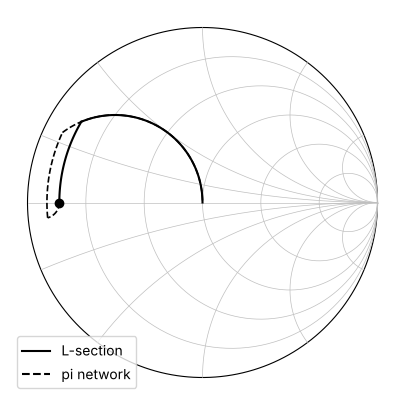

L-section: |Gamma| <= 0.2 from 12.55 to 14.50 MHz (1.95 MHz)
pi network: |Gamma| <= 0.2 from 12.86 to 14.20 MHz (1.34 MHz)


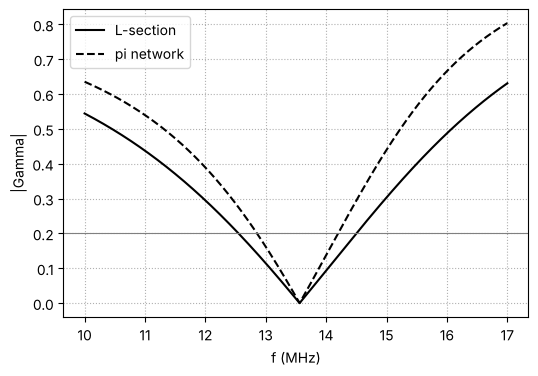

In [6]:
# Subtask 10.3.2 Smith chart and bandwidth
def smith_axes(ax):
    """Smith chart grid: constant-resistance and constant-reactance circles, Z normalised to Z0."""
    t = np.linspace(0, 2 * np.pi, 400)
    ax.plot(np.cos(t), np.sin(t), 'k', lw=0.8)
    for r in (0.2, 0.5, 1.0, 2.0, 5.0):
        c, rad = r / (1 + r), 1 / (1 + r)
        ax.plot(c + rad * np.cos(t), rad * np.sin(t), color='0.75', lw=0.5)
    for x in (0.2, 0.5, 1.0, 2.0, 5.0):
        for s in (1, -1):
            z = 1j * s * x + np.logspace(-3, 3, 600)
            g = (z - 1) / (z + 1)
            ax.plot(g.real, g.imag, color='0.75', lw=0.5)
    ax.plot([-1, 1], [0, 0], color='0.75', lw=0.5)
    ax.set_aspect('equal'); ax.axis('off')


def gamma(z):
    return (z - 1) / (z + 1)


Z0 = 50.0
w3 = 2 * np.pi * f3
s = np.linspace(0, 1, 100)
fig, ax = plt.subplots(figsize=(5, 5))
smith_axes(ax)
# L-section: series L, then shunt C
z1 = 5 / Z0 + 1j * s * w3 * L50 / Z0
y1 = 1 / z1[-1] + 1j * s * w3 * C50 * Z0
ax.plot(gamma(z1).real, gamma(z1).imag, 'k-', lw=1.5, label='L-section')
ax.plot(gamma(1 / y1).real, gamma(1 / y1).imag, 'k-', lw=1.5)
# pi network: shunt C2, series L, shunt C1
y2 = Z0 / 5 + 1j * s * w3 * C2 * Z0
z2 = 1 / y2[-1] + 1j * s * w3 * Lpi / Z0
y3 = 1 / z2[-1] + 1j * s * w3 * C1 * Z0
for seg in (1 / y2, z2, 1 / y3):
    ax.plot(gamma(seg).real, gamma(seg).imag, 'k--', lw=1.2)
ax.plot([], [], 'k--', label='pi network')
ax.plot(gamma(np.array([5 / Z0])).real, [0], 'ko')
ax.legend(loc='lower left'); plt.show()

fs = np.linspace(10e6, 17e6, 7001)
ws = 2 * np.pi * fs
Z_L = 1 / (1j * ws * C50 + 1 / (5 + 1j * ws * L50))
Z_pi = 1 / (1j * ws * C1 + 1 / (1j * ws * Lpi + 1 / (1j * ws * C2 + 1 / 5)))
plt.figure(figsize=(6, 4))
for Z, ls, name in ((Z_L, '-', 'L-section'), (Z_pi, '--', 'pi network')):
    G = np.abs((Z - Z0) / (Z + Z0))
    band = fs[G <= 0.2]
    print(f"{name}: |Gamma| <= 0.2 from {band.min()/1e6:.2f} to {band.max()/1e6:.2f} MHz ({(band.max()-band.min())/1e6:.2f} MHz)")
    plt.plot(fs / 1e6, G, 'k' + ls, label=name)
plt.axhline(0.2, color='gray', lw=0.8)
plt.xlabel('f (MHz)'); plt.ylabel('|Gamma|'); plt.grid(True, ls=':'); plt.legend(); plt.show()


### 10.3 Solution

$33.2~\Omega$ to $8~\Omega$: $Q = 1.78$, $L = 167~\mathrm{nH}$, $C = 627~\mathrm{pF}$, $\eta = 98.6~\%$. $50~\Omega$ to $5~\Omega$: L-section $Q = 3$, $176~\mathrm{nH}$, $704~\mathrm{pF}$, $97.7~\%$; $\pi$ network $R_\mathrm{v} = 2.94~\Omega$, $Q_2 = 0.837$, $C_1 = 939~\mathrm{pF}$, $L = 167~\mathrm{nH}$, $C_2 = 1964~\mathrm{pF}$, $96.3~\%$. In the Smith chart the L-section needs two arcs, the $\pi$ network three, passing close to the short-circuit point ($R_\mathrm{v} < 5~\Omega$). The band with $|\Gamma| \leq 0.2$ is $1.95~\mathrm{MHz}$ wide for the L-section and $1.34~\mathrm{MHz}$ for the $\pi$ network.


## 10.4 Wireless power link for brief B4

$6.78~\mathrm{MHz}$, series compensation, $L_1 = 1.2~\mu\mathrm{H}$, $Q_1 = 250$, $L_2 = 0.8~\mu\mathrm{H}$, $Q_2 = 150$, $k = 0.10 \ldots 0.25$; full-bridge rectifier, $12~\mathrm{V}$, $15~\mathrm{W}$.

10.4.1 Create the functions `get_eta_link(k, R_ac)`, `get_eta_max(k)` and `get_R_prim(k, R_ac)`. Print $R_1$, $R_2$, $C_1$, $C_2$, $R_\mathrm{ac}$ and, for $k = 0.10, 0.18, 0.25$, $U$, $\eta_\mathrm{max}$, the optimum load, $\eta$ with $R_\mathrm{ac}$ and the primary resistance. Plot $\eta$ and $\eta_\mathrm{max}$ versus $k$.

10.4.2 Design a low-pass L-section from the primary at $k = 0.18$ to the $R = 19.84~\Omega$ of the class E of 10.1. Calculate the impedance the inverter sees at $k = 0.10$ and $0.25$ and simulate the class E with it (resistance as $R$, reactance added to the series branch). Print the power, the peak voltage and the voltage at turn-on. Calculate the DC voltage that a half-bridge with series-resonant primary would need for $15~\mathrm{W}$ output at the three couplings.


R1 = 0.204 Ohm, R2 = 0.227 Ohm, C1 = 459 pF, C2 = 689 pF, R_ac = 7.78 Ohm
k = 0.10: U = 19.4, eta_max = 90.2 %, R_opt = 4.41 Ohm, eta(R_ac) = 88.8 %, R_prim = 2.38 Ohm
k = 0.18: U = 34.9, eta_max = 94.4 %, R_opt = 7.92 Ohm, eta(R_ac) = 94.4 %, R_prim = 7.25 Ohm
k = 0.25: U = 48.4, eta_max = 96.0 %, R_opt = 11.00 Ohm, eta(R_ac) = 95.7 %, R_prim = 13.80 Ohm


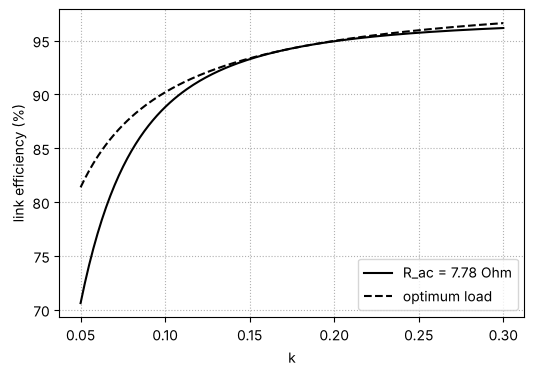

In [7]:
# Subtask 10.4.1 Link efficiency
f4 = 6.78e6
w4 = 2 * np.pi * f4
L1, Q1, L2, Q2 = 1.2e-6, 250.0, 0.8e-6, 150.0
R1, R2 = w4 * L1 / Q1, w4 * L2 / Q2
C1s, C2s = 1 / (w4**2 * L1), 1 / (w4**2 * L2)
R_L = 12.0**2 / 15.0
R_ac = 8 * R_L / np.pi**2


def get_eta_link(k, R_load):
    U2 = k**2 * Q1 * Q2
    x = R_load / R2
    return U2 * x / ((1 + x) * (1 + x + U2))


def get_eta_max(k):
    U2 = k**2 * Q1 * Q2
    return U2 / (1 + np.sqrt(1 + U2))**2, R2 * np.sqrt(1 + U2)


def get_R_prim(k, R_load):
    M = k * np.sqrt(L1 * L2)
    return R1 + (w4 * M)**2 / (R2 + R_load)


print(f"R1 = {R1:.3f} Ohm, R2 = {R2:.3f} Ohm, C1 = {C1s*1e12:.0f} pF, C2 = {C2s*1e12:.0f} pF, R_ac = {R_ac:.2f} Ohm")
for k in (0.10, 0.18, 0.25):
    e_max, R_opt = get_eta_max(k)
    print(f"k = {k:.2f}: U = {k*np.sqrt(Q1*Q2):.1f}, eta_max = {e_max*100:.1f} %, R_opt = {R_opt:.2f} Ohm, "
          f"eta(R_ac) = {get_eta_link(k, R_ac)*100:.1f} %, R_prim = {get_R_prim(k, R_ac):.2f} Ohm")

ks = np.linspace(0.05, 0.3, 200)
plt.figure(figsize=(6, 4))
plt.plot(ks, get_eta_link(ks, R_ac) * 100, 'k-', label='R_ac = 7.78 Ohm')
plt.plot(ks, get_eta_max(ks)[0] * 100, 'k--', label='optimum load')
plt.xlabel('k'); plt.ylabel('link efficiency (%)'); plt.grid(True, ls=':'); plt.legend(); plt.show()


In [8]:
# Subtask 10.4.2 Class E behind a fixed L-section, and the half-bridge alternative
R_p18 = get_R_prim(0.18, R_ac)
QM = np.sqrt(d5['R'] / R_p18 - 1)
X_s, X_p = QM * R_p18, d5['R'] / QM
print(f"L-section {R_p18:.2f} -> {d5['R']:.2f} Ohm: Q = {QM:.3f}, X_s = {X_s:.2f} Ohm ({X_s/w4*1e9:.0f} nH), X_p = {X_p:.2f} Ohm ({1/(w4*X_p)*1e12:.0f} pF)")
X_E = w * d5['L'] - 1 / (w * d5['C0'])
x0 = res[1.0]['x']
for k in (0.10, 0.18, 0.25):
    R_p = get_R_prim(k, R_ac)
    Z = 1 / (1 / (R_p + 1j * X_s) + 1j / X_p)
    C0_k = 1 / (w * (w * d5['L'] - (X_E + Z.imag)))
    r = evaluate(make_period(lambda v: d5['C_sh'], Z.real, d5['L'], C0_k), x0, d5['C_sh'])
    V_hb = np.sqrt(np.pi**2 * R_p * 15.0 / get_eta_link(k, R_ac) / 2)
    print(f"k = {k:.2f}: class E sees {Z.real:.2f} {Z.imag:+.2f}j Ohm: P = {r['P']:.1f} W, V_pk = {r['V_pk']:.1f} V, "
          f"v_on = {r['v_on']:.1f} V | half-bridge: V_DC = {V_hb:.1f} V for 15 W")


L-section 7.25 -> 19.84 Ohm: Q = 1.317, X_s = 9.56 Ohm (224 nH), X_p = 15.06 Ohm (1559 pF)


k = 0.10: class E sees 15.01 +19.65j Ohm: P = 5.0 W, V_pk = 79.8 V, v_on = -0.0 V | half-bridge: V_DC = 14.1 V for 15 W


k = 0.18: class E sees 19.84 +0.00j Ohm: P = 15.1 W, V_pk = 87.4 V, v_on = 0.0 V | half-bridge: V_DC = 23.8 V for 15 W


k = 0.25: class E sees 14.18 -9.40j Ohm: P = 26.9 W, V_pk = 101.1 V, v_on = 7.6 V | half-bridge: V_DC = 32.7 V for 15 W


### 10.4 Solution

$R_1 = 0.204~\Omega$, $R_2 = 0.227~\Omega$, $C_1 = 459~\mathrm{pF}$, $C_2 = 689~\mathrm{pF}$, $R_\mathrm{ac} = 7.78~\Omega$. The link efficiency with $R_\mathrm{ac}$ is $88.8~\%$, $94.4~\%$ and $95.7~\%$ at $k = 0.10$, $0.18$ and $0.25$, close to $\eta_\mathrm{max}$; the rectifier load is optimum near $k = 0.18$. The primary resistance changes from $2.38$ to $13.8~\Omega$. Behind the fixed L-section the class E sees $(15.0 + \mathrm{j}19.7)~\Omega$ at $k = 0.10$ ($5.0~\mathrm{W}$) and $(14.2 - \mathrm{j}9.4)~\Omega$ at $k = 0.25$ ($26.9~\mathrm{W}$, $101~\mathrm{V}$ peak, hard turn-on): the coupling range cannot be covered by a fixed class E. A half-bridge needs $14.1$, $23.8$ and $32.7~\mathrm{V}$: an adjustable supply or regulation on the receiver side.
